### 01. PyTorch Workflow Fundamentals
The essence of machine learning and deep learning is to take some data from the past, build an algorithm (like a neural network) to discover patterns in it and use the discovered patterns to predict the future.

There are many ways to do this and many new ways are being discovered all the time.

But let's start small.

How about we start with a straight line?

And we see if we can build a PyTorch model that learns the pattern of the straight line and matches it.

![Workflow diagram](imgs/01_pytorch_workflow.png)

#### Objective: workflow to predict a simple straight line
![PyTorch Workflow stages](imgs/01_workflow_steps.png)

In [76]:
what_were_covering = {1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}

In [77]:
!pip install matplotlib
!pip install ipywidgets

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Janya\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Janya\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [78]:
import torch
from torch import nn # nn contains all of PyTorch's building blocks for neural networks
import matplotlib.pyplot as plt
# Check PyTorch version
torch.__version__

'2.14.1+cpu'

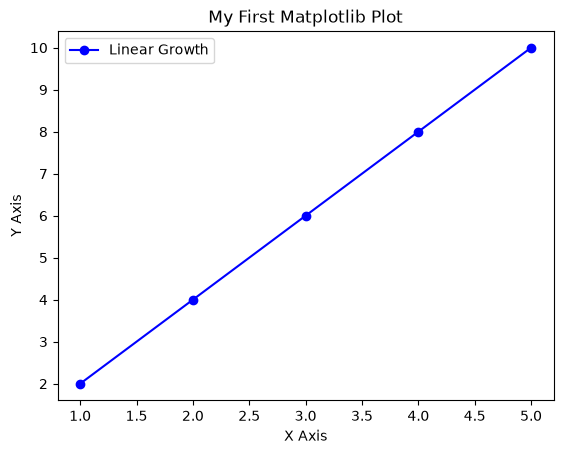

In [79]:
# Check matplotlib is working

import matplotlib.pyplot as plt

# 1. Create simple data points
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]

# 2. Plot the data
plt.plot(x, y, label="Linear Growth", color="blue", marker="o")

# 3. Add titles and labels
plt.title("My First Matplotlib Plot")
plt.xlabel("X Axis")
plt.ylabel("Y Axis")
plt.legend()

# 4. Display the graph
plt.show()


#### Tow parts of the Machine learning:
* Represent the data into numberical format
* Build a model to learn the representation as best as possible.

***Objective:  Create our data as a straight line.***

We'll use linear regression to create the data with known parameters (things that can be learned by a model) and then we'll use PyTorch to see if we can build model to estimate these parameters using gradient descent.



In [80]:
# Stright line function: y = mx + c 
weight = 0.7
bias =0.3

# create data
start=0
end=1
step=0.02
X = torch.arange(start,end, step).unsqueeze(dim=1)
y = weight*X + bias

X[:10], y[:10]

# NOTE: Now, this is building a model that can learn the relationship between X (features) and y (labels).

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

#### Split data into training and test sets
![Train Test data split](imgs/01_train_test_split.png)

***Note: When dealing with real-world data, this step is typically done right at the start of a project (the test set should always be kept separate from all other data). We want our model to learn from training data and then evaluate it on test data to get an indication of how well it generalizes to unseen examples.***


In [81]:
train_split = int(0.8*len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test=X[train_split:], y[train_split:]
print(f"Train X size:{len(X_train)}, Train x size:{len(y_train)}, Test X size:{len(X_test)}, Test Y size:{len(y_test)}")


Train X size:40, Train x size:40, Test X size:10, Test Y size:10


 we've got 40 samples for training (X_train & y_train) and 10 samples for testing (X_test & y_test).

The model we create is going to try and learn the relationship between X_train & y_train and then we will evaluate what it learns on X_test and y_test.

In [82]:
def plot_predictions(train_data=X_train, 
                     train_labels=y_train, 
                     test_data=X_test, 
                     test_labels=y_test, 
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")
  
  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14});

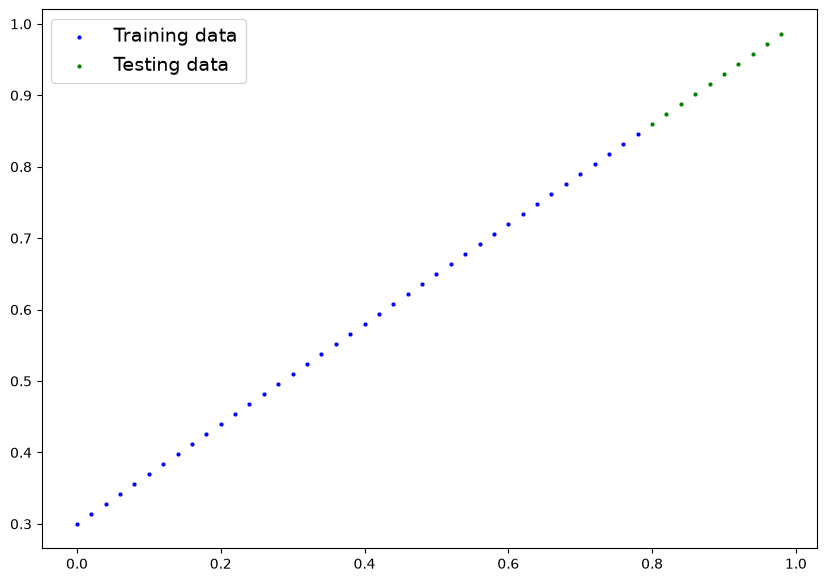

In [83]:
plot_predictions()

In [84]:
help(plt.scatter)

Help on function scatter in module matplotlib.pyplot:

scatter(
    x: 'float | ArrayLike',
    y: 'float | ArrayLike',
    s: 'float | ArrayLike | None' = None,
    c: 'ArrayLike | Sequence[ColorType] | ColorType | None' = None,
    *,
    marker: 'MarkerType | None' = None,
    cmap: 'str | Colormap | None' = None,
    norm: 'str | Normalize | None' = None,
    vmin: 'float | None' = None,
    vmax: 'float | None' = None,
    alpha: 'float | None' = None,
    linewidths: 'float | Sequence[float] | None' = None,
    edgecolors: "Literal['face', 'none'] | ColorType | Sequence[ColorType] | None" = None,
    colorizer: 'Colorizer | None' = None,
    plotnonfinite: 'bool' = False,
    data: 'DataParamType' = None,
    **kwargs
) -> 'PathCollection'
    A scatter plot of *y* vs. *x* with varying marker size and/or color.

    Parameters
    ----------
    x, y : float or array-like, shape (n, )
        The data positions.

    s : float or array-like, shape (n, ), optional
        The mark

#### 2. Build model
Now we've got some data, let's build a model to use the blue dots to predict the green dots.

We're going to jump right in.

We'll write the code first and then explain everything.

Let's replicate a standard linear regression model using pure PyTorch.

In [85]:
# Create a Linear Regression Model class
from typing import Any


class LinearRegrModel(nn.Module):
    def __init__(self, *args: Any, **kwargs: Any) -> None:
        super().__init__(*args, **kwargs)
        self.weights = nn.Parameter(torch.randn(1, # Start with random weight
                                               dtype=torch.float, # default float32
                                               requires_grad=True # weight gets updated with gradient decent
                                               ))
        self.bias = nn.Parameter(torch.randn(1, # <- start with random bias (this will get adjusted as the model learns)
                                            dtype=torch.float), # <- PyTorch loves float32 by default
                                requires_grad=True) # <- can we update this value with gradient descent?))
        
    def forward(self, X:torch.Tensor) -> torch.Tensor: # x is the input train data
        return self.weights *X + self.bias # linear regression formula (y = m*x + b)
    







#### PyTorch model building essentials
* PyTorch has four (give or take) essential modules you can use to create almost any kind of neural network you can imagine.

* They are ****torch.nn, torch.optim, torch.utils.data.Dataset and torch.utils.data.DataLoader*** . For now, we'll focus on the first two and get to the other two later (though you may be able to guess what they do).

![PyTorch essential NN Modules](imgs/01_pytorch_imp_nn_modules.png)

If the above sounds complex, think of like this, almost everything in a PyTorch neural network comes from torch.nn,

* nn.Module contains the larger building blocks (layers)
* nn.Parameter contains the smaller parameters like weights and biases (put these together to make nn.Module(s))
* forward() tells the larger blocks how to make calculations on inputs (tensors full of data) within nn.Module(s)
* torch.optim contains optimization methods on how to improve the parameters within nn.Parameter to better represent input data

![Linear Regreesion Class](imgs/01_linear_regr_class.png)

Basic building blocks of creating a PyTorch model by subclassing nn.Module. For objects that subclass nn.Module, the forward() method must be defined.



#### Checking the contents of a PyTorch model

In [86]:
# Set manual seed since nn.Parameter are randomly initialized
torch.manual_seed(42)

# Create an instance of the model (this is a subclass of nn.Module that contains nn.Parameter(s))
model_0 = LinearRegrModel()

# Check the nn.Parameter(s) within the nn.Module subclass we created
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [87]:
# List named parameters 
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

* Essentially we want to start from random parameters and get the model to update them towards parameters that fit our data best (the hardcoded weight and bias values we set when creating our straight line data).

* Exercise: Try changing the torch.manual_seed() value two cells above, see what happens to the weights and bias values.
* Output: weight and bias initialized random weight, other that earlier value

#### Making predictions using torch.inference_mode()

To check this we can pass it the test data X_test to see how closely it predicts y_test.

When we pass data to our model, it'll go through the model's forward() method and produce a result using the computation we've defined.




In [88]:
# Make predictions with model
with torch.inference_mode(): 
    y_preds = model_0(X_test)

# Note: in older PyTorch code you might also see torch.no_grad()
# with torch.no_grad():
#   y_preds = model_0(X_test)

***torch.inference_mode() turns off a bunch of things (like gradient tracking, which is necessary for training but not for inference) to make forward-passes (data going through the forward() method) faster.***

In [89]:
# Check the predictions
print(f"Number of testing samples: {len(X_test)}") 
print(f"Number of predictions made: {len(y_preds)}")
print(f"Predicted values:\n{y_preds}")

Number of testing samples: 10
Number of predictions made: 10
Predicted values:
tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])


#### visualize them with our plot_predictions() function we created above

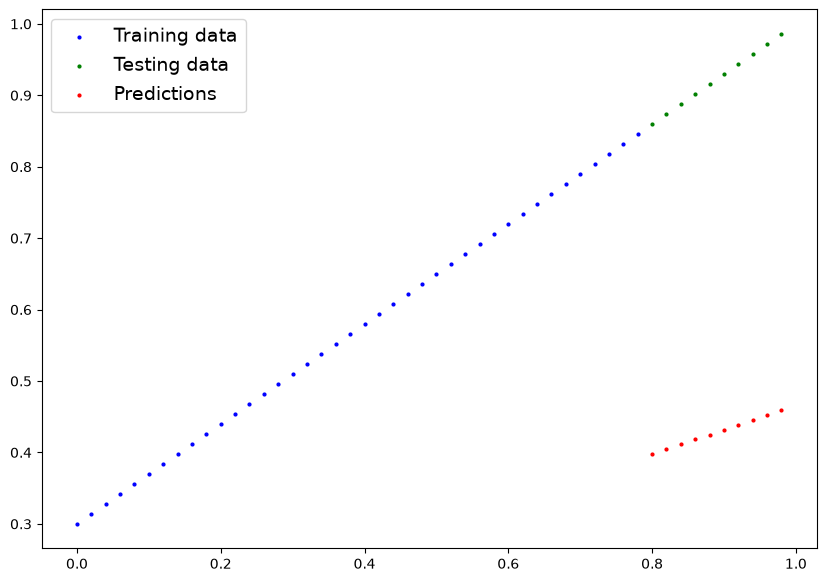

In [90]:
plot_predictions(predictions=y_preds)


In [91]:
y_test - y_preds



tensor([[0.4618],
        [0.4691],
        [0.4764],
        [0.4836],
        [0.4909],
        [0.4982],
        [0.5054],
        [0.5127],
        [0.5200],
        [0.5272]])

In [92]:
y_test

tensor([[0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

In [93]:
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

* Output:
* predictions look pretty bad...
* Remember our model is just using random parameter values to make predictions.
* It hasn't even looked at the blue dots to try to predict the green dots.


#### 3. Train model
* Right now our model is making predictions using random parameters to make calculations, it's basically guessing (randomly).

* To fix that, we can update its internal parameters (I also refer to parameters as patterns), the weights and bias values we set randomly using nn.Parameter() and torch.randn() to be something that better represents the data.

* We could hard code this (since we know the default values weight=0.7 and bias=0.3) but where's the fun in that?

* Much of the time you won't know what the ideal parameters are for a model.

* Instead, it's much more fun to write code to see if the model can try and figure them out itself.

#### Creating a loss function and optimizer in PyTorch
* For our model to update its parameters on its own, we'll need to add a few more things to our recipe.

* And that's a loss function as well as an optimizer.

The rolls of these are:

![Loss Fn & Optimizer](imgs/01_lossfn_optimizer.png)


* Depending on what kind of problem you're working on will depend on what loss function and what optimizer you use.

* However, there are some common values, that are known to work well such as the SGD (stochastic gradient descent) or Adam optimizer. And the MAE (mean absolute error) loss function for regression problems (predicting a number) or binary cross entropy loss function for classification problems (predicting one thing or another).

* For our problem, since we're predicting a number, let's use MAE (which is under torch.nn.L1Loss()) in PyTorch as our loss function.

![MAE Loss](imgs/01_mae_loss.png)

* Mean absolute error (MAE, in PyTorch: torch.nn.L1Loss) measures the absolute difference between two points (predictions and labels) and then takes the mean across all examples.

* And we'll use SGD, torch.optim.SGD(params, lr) where:

* params is the target model parameters you'd like to optimize (e.g. the weights and bias values we randomly set before).

* lr is the learning rate you'd like the optimizer to update the parameters at, higher means the optimizer will try larger updates (these can sometimes be too large and the optimizer will fail to work), lower means the optimizer will try smaller updates (these can sometimes be too small and the optimizer will take too long to find the ideal values). The learning rate is considered a hyperparameter (because it's set by a machine learning engineer).*** Common starting values for the learning rate are 0.01, 0.001, 0.0001, *** however, these can also be adjusted over time (this is called learning rate scheduling).


In [94]:
# create loss fn
loss_fn = nn.L1Loss() # MAE loss is same as L1Loss
# create the optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(), # # parameters of target model to optimize
                            lr=0.01 ## learning rate (how much the optimizer should change parameters at each step, higher=more (less stable), lower=less (might take a long time))

)

#### Creating an optimization loop in PyTorch
* Now we've got a loss function and an optimizer, it's now time to create a training loop (and testing loop).

* The training loop involves the model going through the training data and learning the relationships between the features and labels.

* The testing loop involves going through the testing data and evaluating how good the patterns are that the model learned on the training data (the model never sees the testing data during training).

* Each of these is called a "loop" because we want our model to look (loop through) at each sample in each dataset.

#### PyTorch training loop
For the training loop, we'll build the following steps:
![Pytorch training loop](imgs/01_pytorch_training_loop.png)
![Pytorch training loop steps](imgs/01_pytorch_train_loop_steps.png)


* Note: The above is just one example of how the steps could be ordered or described. With experience you'll find making PyTorch training loops can be quite flexible.

* And on the ordering of things, the above is a good default order but you may see slightly different orders. Some rules of thumb:

* Calculate the loss (loss = ...) before performing backpropagation on it (loss.backward()).
* Zero gradients (optimizer.zero_grad()) before computing the gradients of the loss with respect to every model parameter (loss.backward()).
* Step the optimizer (optimizer.step()) after performing backpropagation on the loss (loss.backward()).

* For resources to help understand what's happening behind the scenes with backpropagation and gradient descent, see the extra-curriculum section.






#### PyTorch testing loop
As for the testing loop (evaluating our model), the typical steps include:



Notice the testing loop doesn't contain performing backpropagation (loss.backward()) or stepping the optimizer (optimizer.step()), this is because no parameters in the model are being changed during testing, they've already been calculated. For testing, we're only interested in the output of the forward pass through the model.

![Pytorch Test loop](imgs/01_pytorch_test_loop_steps.png)




In [95]:
torch.manual_seed(42)

# set the no of epochs
epochs = 100

# create empty loss lists to track vals
train_loss_values = []
test_loss_values = []
epochs_count = []

for epoch in range(epochs):
    ### Model training

    #Put model in training mode
    model_0.train()

    # 1 . Forward pass on train data using the forward() 
    y_pred = model_0(X_train)

    # 2. calculate tge loss
    loss = loss_fn(y_pred, y_train)

    #3.zero grad of the optimizer
    optimizer.zero_grad()

    #4. Loss backward
    loss.backward()

    # 5 . progress the optimizer
    optimizer.step()

    #### Testing
    # Put the model in eval mode
    model_0.eval()

    with torch.inference_mode():
        #1. Forard pass on test data
        test_pred = model_0(X_test)

        #2. calculate loss on test data
        test_loss = loss_fn(test_pred, y_test.type(torch.float))

        # Print epoch progress
        if epoch % 10 == 0:
            epochs_count.append(epoch)
            train_loss_values.append(loss.detach().numpy())
            test_loss_values.append(test_loss.detach().numpy())
            print(f"Epoch: {epoch}| MAE Train loss: {loss} | MAE Test loss : {test_loss}")





Epoch: 0| MAE Train loss: 0.31288138031959534 | MAE Test loss : 0.48106518387794495
Epoch: 10| MAE Train loss: 0.1976713240146637 | MAE Test loss : 0.3463551998138428
Epoch: 20| MAE Train loss: 0.08908725529909134 | MAE Test loss : 0.21729660034179688
Epoch: 30| MAE Train loss: 0.053148526698350906 | MAE Test loss : 0.14464017748832703
Epoch: 40| MAE Train loss: 0.04543796554207802 | MAE Test loss : 0.11360953003168106
Epoch: 50| MAE Train loss: 0.04167863354086876 | MAE Test loss : 0.09919948130846024
Epoch: 60| MAE Train loss: 0.03818932920694351 | MAE Test loss : 0.08886633068323135
Epoch: 70| MAE Train loss: 0.03476089984178543 | MAE Test loss : 0.0805937647819519
Epoch: 80| MAE Train loss: 0.03132382780313492 | MAE Test loss : 0.07232122868299484
Epoch: 90| MAE Train loss: 0.02788739837706089 | MAE Test loss : 0.06473556160926819


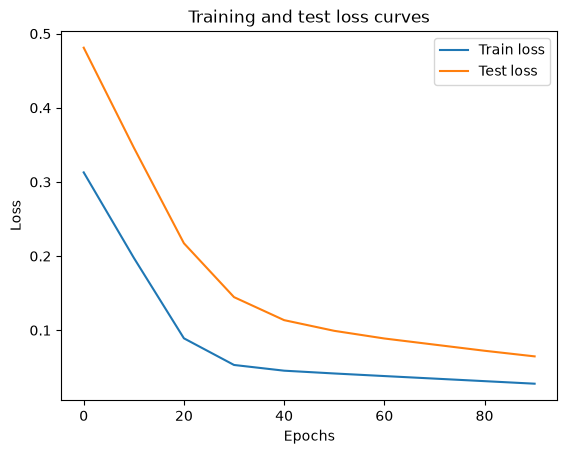

In [96]:
# Plot the loss curves
plt.plot(epochs_count, train_loss_values, label="Train loss")
plt.plot(epochs_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

Nice! The loss curves show the loss going down over time. Remember, loss is the measure of how wrong your model is, so the lower the better.

But why did the loss go down?

Well, thanks to our loss function and optimizer, the model's internal parameters (weights and bias) were updated to better reflect the underlying patterns in the data.

Let's inspect our model's .state_dict() to see how close our model gets to the original values we set for weights and bias.

In [97]:
# Find our model's learned parameters
print("The model learned the following values for weights and bias:")
print(model_0.state_dict())
print("\nAnd the original values for weights and bias are:")
print(f"weights: {weight}, bias: {bias}")

The model learned the following values for weights and bias:
OrderedDict({'weights': tensor([0.5784]), 'bias': tensor([0.3513])})

And the original values for weights and bias are:
weights: 0.7, bias: 0.3


Our model got very close to calculating the exact original values for weight and bias (and it would probably get even closer if we trained it for longer).

Exercise: Try changing the epochs value above to 200, what happens to the loss curves and the weights and bias parameter values of the model?

***This is the whole idea of machine learning and deep learning, there are some ideal values that describe our data and rather than figuring them out by hand, we can train a model to figure them out programmatically.***